# Displacement interpolation

Let distribution $\mu_{0}$ be a Gaussian and $\mu_{1}$ be a mixture of two Gaussians. We want to obtain the displacement interpolation $\mu_{t}$.

In [2]:
from scipy.stats import norm

# Distributions μ0 and μ1
m0, s0 = -3.0, 1.0
params1 = [(0.5, 3.0, 0.7), (0.5, 7.0, 0.7)] # (weight, mean, std)

def p0(x):
    return norm.pdf(x, m0, s0)

def p1(x):
    return sum(w * norm.pdf(x, m, s) for (w, m, s) in params1)

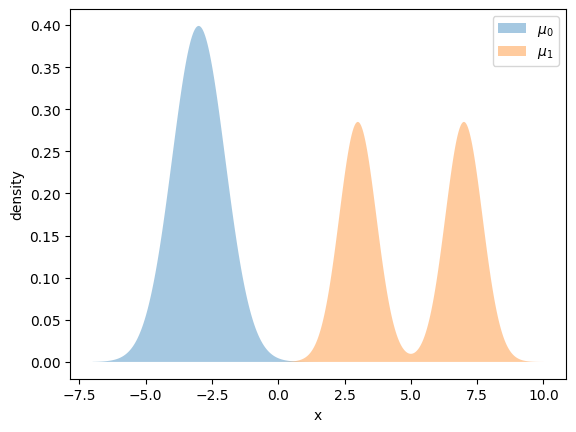

In [3]:
import numpy as np
from matplotlib import pyplot as plt

x = np.linspace(-7, 10, 1000)

fig, ax = plt.subplots()
ax.fill_between(x, p0(x), alpha=0.4, label=r"$\mu_0$")
ax.fill_between(x, p1(x), alpha=0.4, label=r"$\mu_1$")
ax.set_xlabel("x")
ax.set_ylabel("density")
ax.legend()
plt.show()

## Optimal transport in 1D

Consider a cost $c:X\times Y\to[0,+\infty]$. For any $x\lt x'$ and $y\lt y'$, suppose the cost satisfies the following property:

$$
c(x,y)+c(x',y')\leq c(x,y')+c(x',y).
$$

This means crossing pairs never beat non-crossing pairs. And this allows us to express the optimal map in 1D using CDFs and quantile functions. If there is $10\%$ of the mass left to $x$, then there must be $10\%$ of the mass left to $T(x)$. Let's denote the CDF of $\mu_{0}$ as $F_{0}$ and the quantile function of $\mu_{1}$ as $Q_{1}$. Then the optimal map can be expressed as

$$
T(x)=Q_{1}(F_{0}(x)).
$$

In [2]:
from scipy.stats import norm